In [1]:
import pandas as pd
from scipy.sparse import load_npz

X_train = load_npz("../data/X_train_tfidf.npz")
X_test = load_npz("../data/X_test_tfidf.npz")
y_train = pd.read_csv("../data/y_train.csv").iloc[:, 0]
y_test = pd.read_csv("../data/y_test.csv").iloc[:, 0]
X_train_bow = load_npz("../data/X_train_bow.npz")
X_test_bow = load_npz("../data/X_test_bow.npz")

print(X_train.shape, X_test.shape, len(y_train), len(y_test))

(40000, 20000) (10000, 20000) 40000 10000


In [2]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, f1_score, classification_report

for name, Xtrain, Xtest in [("TF-IDF", X_train, X_test), ("BoW", X_train_bow, X_test_bow)]:
    nb = MultinomialNB()
    nb.fit(Xtrain, y_train)
    preds = nb.predict(Xtest)
    print(f"--- Naive Bayes on {name} ---")
    print("Accuracy:", round(accuracy_score(y_test, preds), 4))
    print("Macro F1:", round(f1_score(y_test, preds, average="macro"), 4))
    print(classification_report(y_test, preds, digits=3))

--- Naive Bayes on TF-IDF ---
Accuracy: 0.7908
Macro F1: 0.3442
              precision    recall  f1-score   support

    Negative      0.895     0.082     0.151      1446
     Neutral      0.000     0.000     0.000       752
    Positive      0.790     0.998     0.882      7802

    accuracy                          0.791     10000
   macro avg      0.561     0.360     0.344     10000
weighted avg      0.745     0.791     0.710     10000

--- Naive Bayes on BoW ---
Accuracy: 0.8262
Macro F1: 0.5963
              precision    recall  f1-score   support

    Negative      0.621     0.620     0.620      1446
     Neutral      0.344     0.211     0.262       752
    Positive      0.890     0.924     0.907      7802

    accuracy                          0.826     10000
   macro avg      0.618     0.585     0.596     10000
weighted avg      0.810     0.826     0.817     10000



Baseline accuracy: 0.7802
Baseline macro F1: 0.2922


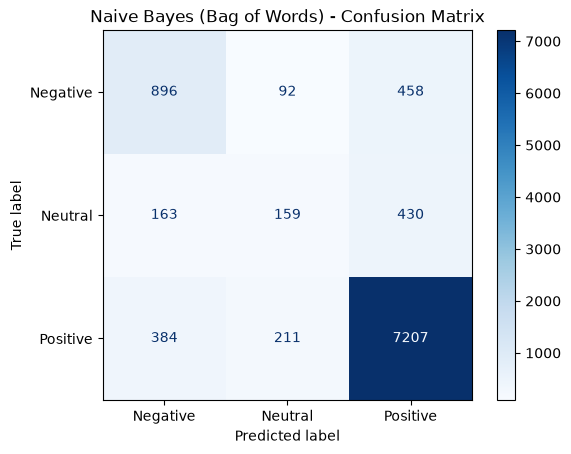

In [3]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import os

base = DummyClassifier(strategy="most_frequent").fit(X_train_bow, y_train)
base_preds = base.predict(X_test_bow)
print("Baseline accuracy:", round(accuracy_score(y_test, base_preds), 4))
print("Baseline macro F1:", round(f1_score(y_test, base_preds, average="macro"), 4))

nb_bow = MultinomialNB().fit(X_train_bow, y_train)
bow_preds = nb_bow.predict(X_test_bow)

os.makedirs("../report/figures", exist_ok=True)
ConfusionMatrixDisplay.from_predictions(y_test, bow_preds, cmap="Blues")
plt.title("Naive Bayes (Bag of Words) - Confusion Matrix")
plt.savefig("../report/figures/nb_bow_confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

In [4]:
import joblib, numpy as np

vec = joblib.load("../data/vectorizers.joblib")
print(type(vec))
if isinstance(vec, dict):
    print(vec.keys())
    bow_vec = [v for k, v in vec.items() if "bow" in k.lower() or "count" in k.lower()][0]
else:
    bow_vec = vec
words = bow_vec.get_feature_names_out()

classes = list(nb_bow.classes_)
pos, neg = classes.index("Positive"), classes.index("Negative")
ratio = nb_bow.feature_log_prob_[pos] - nb_bow.feature_log_prob_[neg]

top_pos = words[np.argsort(ratio)[-10:][::-1]]
top_neg = words[np.argsort(ratio)[:10]]
print("Top positive:", list(top_pos))
print("Top negative:", list(top_neg))

os.makedirs("../results", exist_ok=True)
pd.DataFrame({"top_positive": top_pos, "top_negative": top_neg}).to_csv("../results/top_features.csv", index=False)

wrong = pd.DataFrame({"true": y_test.values, "predicted": bow_preds})
wrong = wrong[wrong["true"] != wrong["predicted"]]
wrong.to_csv("../results/misclassified.csv")
print(len(wrong), "misclassified reviews saved")

<class 'dict'>
dict_keys(['bow_vectorizer', 'tfidf_vectorizer'])
Top positive: ['soothing', 'hawaii', 'pleasantly', 'matcha', 'schedule', 'pb2', 'hooked', 'relax', 'calm', 'overweight']
Top negative: ['housemate', 'unmeasured', 'buffoon', 'parsing', 'vile', 'deliberately', 'ripoff', 'kaboodle', 'slaughterhouse', 'trashing']
1738 misclassified reviews saved


c:\Users\brand\Desktop\repos\school\cse3521-sentiment-analysis\.venv\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator CountVectorizer from version 1.6.1 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\Users\brand\Desktop\repos\school\cse3521-sentiment-analysis\.venv\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator TfidfTransformer from version 1.6.1 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\Users\brand\Desktop\repos\school\cse3521-sentiment-analysis\.venv\Lib\site-packages\sklearn\base.py:525: Inconsist

In [5]:
counts = np.asarray(X_train_bow.sum(axis=0)).ravel()
common = counts >= 250

r = np.where(common, ratio, np.nan)
order = np.argsort(r)
valid = order[~np.isnan(r[order])]

top_pos = words[valid[-10:][::-1]]
top_neg = words[valid[:10]]
print("Top positive:", list(top_pos))
print("Top negative:", list(top_neg))

pd.DataFrame({"top_positive": top_pos, "top_negative": top_neg}).to_csv("../results/top_features.csv", index=False)

Top positive: ['matcha', 'hooked', 'beat', 'yum', 'delicious', 'yummy', 'refreshing', 'perfect', 'highly', 'keeps']
Top negative: ['worst', 'return', 'awful', 'horrible', 'terrible', 'china', 'nasty', 'stale', 'waste', 'description']


In [6]:
os.makedirs("../models", exist_ok=True)
joblib.dump(nb_bow, "../models/nb_bow_model.joblib")
print("Saved model")

Saved model


In [7]:
import time
from sklearn.linear_model import LogisticRegression

lr_results = {}
for name, Xtr, Xte in [("BoW", X_train_bow, X_test_bow), ("TF-IDF", X_train, X_test)]:
    lr = LogisticRegression(max_iter=1000)
    start = time.time()
    lr.fit(Xtr, y_train)
    train_time = time.time() - start

    preds = lr.predict(Xte)
    print(f"--- Logistic Regression on {name} (trained in {train_time:.1f}s) ---")
    print("Accuracy:", round(accuracy_score(y_test, preds), 4))
    print("Macro F1:", round(f1_score(y_test, preds, average="macro"), 4))
    print(classification_report(y_test, preds, digits=3))
    lr_results[name] = (lr, preds, train_time)

--- Logistic Regression on BoW (trained in 3.8s) ---
Accuracy: 0.847
Macro F1: 0.6267
              precision    recall  f1-score   support

    Negative      0.688     0.652     0.670      1446
     Neutral      0.355     0.242     0.288       752
    Positive      0.905     0.941     0.923      7802

    accuracy                          0.847     10000
   macro avg      0.649     0.612     0.627     10000
weighted avg      0.832     0.847     0.838     10000

--- Logistic Regression on TF-IDF (trained in 2.8s) ---
Accuracy: 0.8563
Macro F1: 0.5948
              precision    recall  f1-score   support

    Negative      0.735     0.607     0.665      1446
     Neutral      0.536     0.120     0.196       752
    Positive      0.879     0.974     0.924      7802

    accuracy                          0.856     10000
   macro avg      0.717     0.567     0.595     10000
weighted avg      0.833     0.856     0.832     10000



In [8]:
joblib.dump(lr_results["BoW"][0], "../models/lr_bow_model.joblib")
joblib.dump(lr_results["TF-IDF"][0], "../models/lr_tfidf_model.joblib")
print("Saved both Logistic Regression models")

Saved both Logistic Regression models


In [ ]:
from sklearn.model_selection import train_test_split

Xtr_sub, Xval, ytr_sub, yval = train_test_split(
    X_train_bow, y_train, test_size=0.1, stratify=y_train, random_state=43)

rows = []
for C in [0.1, 0.3, 1, 3]:
    for cw in ["none", "balanced"]:
        m = LogisticRegression(C=C, class_weight=None if cw == "none" else "balanced", max_iter=1000)
        m.fit(Xtr_sub, ytr_sub)
        f1 = f1_score(yval, m.predict(Xval), average="macro")
        rows.append({"C": C, "class_weight": cw, "val_macro_f1": round(f1, 4)})
        print(C, cw, round(f1, 4))

tuning = pd.DataFrame(rows).sort_values("val_macro_f1", ascending=False)
tuning

0.1 none 0.6069
0.1 balanced 0.6221
0.3 none 0.62
0.3 balanced 0.6215
1 none 0.6287
1 balanced 0.6146
3 none 0.6298
3 balanced 0.6141


,C,class_weight,val_macro_f1
6,3.0,none,0.6298
4,1.0,none,0.6287
1,0.1,balanced,0.6221
3,0.3,balanced,0.6215
2,0.3,none,0.6200
5,1.0,balanced,0.6146
7,3.0,balanced,0.6141
0,0.1,none,0.6069


Best: {'C': np.float64(3.0), 'class_weight': 'none', 'val_macro_f1': np.float64(0.6298)}
Trained in 3.6s
Accuracy: 0.8386
Macro F1: 0.6237
              precision    recall  f1-score   support

    Negative      0.663     0.651     0.657      1446
     Neutral      0.327     0.269     0.295       752
    Positive      0.910     0.928     0.919      7802

    accuracy                          0.839     10000
   macro avg      0.633     0.616     0.624     10000
weighted avg      0.830     0.839     0.834     10000



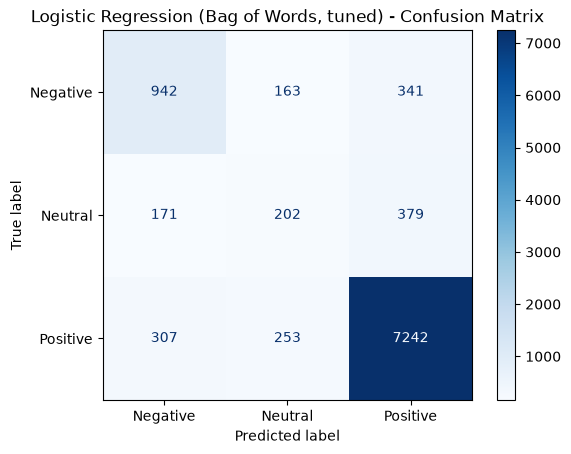

In [10]:
best = tuning.iloc[0]
print("Best:", dict(best))

lr_best = LogisticRegression(C=best["C"], class_weight=None if best["class_weight"] == "none" else "balanced", max_iter=1000)
start = time.time()
lr_best.fit(X_train_bow, y_train)
lr_time = time.time() - start

lr_preds = lr_best.predict(X_test_bow)
print(f"Trained in {lr_time:.1f}s")
print("Accuracy:", round(accuracy_score(y_test, lr_preds), 4))
print("Macro F1:", round(f1_score(y_test, lr_preds, average="macro"), 4))
print(classification_report(y_test, lr_preds, digits=3))

ConfusionMatrixDisplay.from_predictions(y_test, lr_preds, cmap="Blues")
plt.title("Logistic Regression (Bag of Words, tuned) - Confusion Matrix")
plt.savefig("../report/figures/lr_bow_confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

joblib.dump(lr_best, "../models/lr_bow_model.joblib")
tuning.to_csv("../results/lr_tuning.csv", index=False)

In [11]:
import copy
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import log_loss

Xtr_nn, Xval_nn, ytr_nn, yval_nn = train_test_split(
    X_train, y_train, test_size=0.1, stratify=y_train, random_state=43)

mlp = MLPClassifier(hidden_layer_sizes=(128,), activation="relu", solver="adam",
                    learning_rate_init=0.001, batch_size=64, alpha=1e-4, random_state=43)
classes = np.unique(y_train)

train_losses, val_losses = [], []
best_val, best_model, bad, patience = float("inf"), None, 0, 3
start = time.time()
for epoch in range(1, 21):
    mlp.partial_fit(Xtr_nn, ytr_nn, classes=classes)
    tl = log_loss(ytr_nn, mlp.predict_proba(Xtr_nn), labels=mlp.classes_)
    vl = log_loss(yval_nn, mlp.predict_proba(Xval_nn), labels=mlp.classes_)
    train_losses.append(tl)
    val_losses.append(vl)
    print(f"Epoch {epoch}: train loss {tl:.4f}, val loss {vl:.4f}")
    if vl < best_val:
        best_val, best_model, bad = vl, copy.deepcopy(mlp), 0
    else:
        bad += 1
        if bad >= patience:
            print("Early stopping: validation loss stopped improving")
            break
nn_time = time.time() - start

Epoch 1: train loss 0.2966, val loss 0.3924
Epoch 2: train loss 0.2019, val loss 0.3998
Epoch 3: train loss 0.1403, val loss 0.4456
Epoch 4: train loss 0.0969, val loss 0.5053
Early stopping: validation loss stopped improving


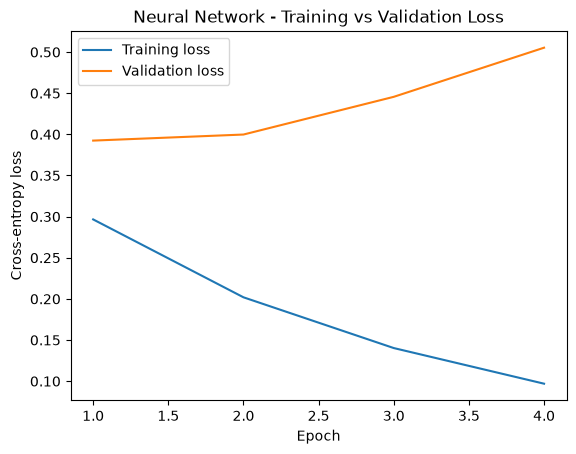

Trained in 178.7s
Accuracy: 0.8565
Macro F1: 0.5473
              precision    recall  f1-score   support

    Negative      0.676     0.687     0.682      1446
     Neutral      0.619     0.017     0.034       752
    Positive      0.888     0.969     0.927      7802

    accuracy                          0.857     10000
   macro avg      0.728     0.558     0.547     10000
weighted avg      0.837     0.857     0.824     10000



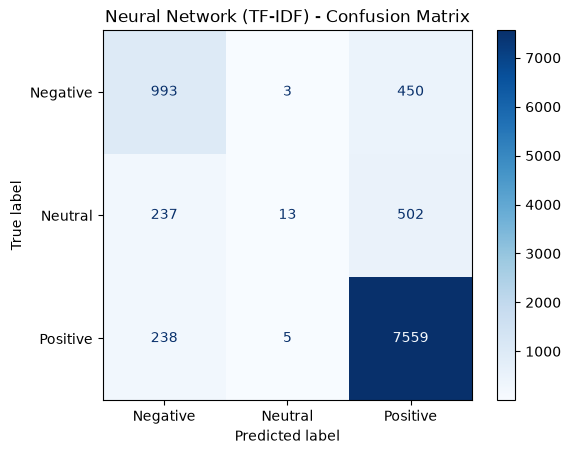

['../models/nn_tfidf_model.joblib']

In [12]:
plt.figure()
plt.plot(range(1, len(train_losses) + 1), train_losses, label="Training loss")
plt.plot(range(1, len(val_losses) + 1), val_losses, label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.title("Neural Network - Training vs Validation Loss")
plt.legend()
plt.savefig("../report/figures/nn_loss_curves.png", dpi=150, bbox_inches="tight")
plt.show()

nn_preds = best_model.predict(X_test)
print(f"Trained in {nn_time:.1f}s")
print("Accuracy:", round(accuracy_score(y_test, nn_preds), 4))
print("Macro F1:", round(f1_score(y_test, nn_preds, average="macro"), 4))
print(classification_report(y_test, nn_preds, digits=3))

ConfusionMatrixDisplay.from_predictions(y_test, nn_preds, cmap="Blues")
plt.title("Neural Network (TF-IDF) - Confusion Matrix")
plt.savefig("../report/figures/nn_confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

joblib.dump(best_model, "../models/nn_tfidf_model.joblib")

In [13]:
from sklearn.metrics import precision_recall_fscore_support, recall_score

start = time.time()
MultinomialNB().fit(X_train_bow, y_train)
nb_time = time.time() - start

models = [
    ("Naive Bayes (BoW)", bow_preds, nb_time),
    ("Logistic Regression (TF-IDF, default)", lr_results["TF-IDF"][1], lr_results["TF-IDF"][2]),
    ("Logistic Regression (BoW, tuned C=3)", lr_preds, lr_time),
    ("Neural Network (TF-IDF, 128 hidden)", nn_preds, nn_time),
]

rows = []
for name, preds, t in models:
    p, r, f, _ = precision_recall_fscore_support(y_test, preds, average="macro", zero_division=0)
    neu = recall_score(y_test, preds, labels=["Neutral"], average=None)[0]
    rows.append({"Model": name,
                 "Accuracy": round(accuracy_score(y_test, preds), 3),
                 "Macro precision": round(p, 3),
                 "Macro recall": round(r, 3),
                 "Macro F1": round(f, 3),
                 "Neutral recall": round(neu, 3),
                 "Training time (s)": round(t, 1)})

comparison = pd.DataFrame(rows)
comparison.to_csv("../results/model_comparison.csv", index=False)
comparison

,Model,Accuracy,Macro precision,Macro recall,Macro F1,Neutral recall,Training time (s)
0,Naive Bayes (BoW),0.826,0.618,0.585,0.596,0.211,0.2
1,"Logistic Regression (TF-IDF, default)",0.856,0.717,0.567,0.595,0.120,2.8
2,"Logistic Regression (BoW, tuned C=3)",0.839,0.633,0.616,0.624,0.269,3.6
3,"Neural Network (TF-IDF, 128 hidden)",0.857,0.728,0.558,0.547,0.017,178.7
